In [1]:
import numpy as np
import torch.nn.functional as F
import matplotlib.pyplot as plt
import torch

#### building out the dataset

In [2]:
words = open('../names.txt', 'r').read().splitlines()

In [3]:
letters = sorted(list(set(''.join(words))))
str_to_int = {s:i+1 for i, s in enumerate(letters)}
str_to_int['.'] = 0
int_to_str = {i:s for s, i in str_to_int.items()}
vocab_size = len(int_to_str)

In [4]:
def build_dataset(words):
    context_length = 3
    X, Y = [], []

    for word in words:
        context = [0] * context_length
        for character in word + '.':
            index = str_to_int[character]
            Y.append(index)
            X.append(context)
            context = context[1:] + [index]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(1234)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtrain, Ytrain = build_dataset(words[:n1])
Xval, Yval = build_dataset(words[n1:n2])
Xtest, Ytest = build_dataset(words[:n1])

#### Layer Classes

In [5]:
class Linear:
    def __init__(self, n_inputs, n_outputs, bias = False):
        self.weights = torch.randn(n_inputs, n_outputs) * (1 / n_inputs**0.5)
        self.bias = torch.zeros(n_outputs) if bias else None

    def __call__(self, x):
        self.out = x @ self.weights 
        if self.bias is not None:
            self.out += self.bias 
        return self.out

    def parameters(self):
        return [self.weights] + ([self.bias] if self.bias is not None else [])

In [6]:
class Batch_Normalisation:
    def __init__(self, dim, eps = 1e-5, momentum = 0.1):
        self.eps = eps
        self.momentum = momentum
        self.training  = True
        self.gamma = torch.ones(dim)
        self.beta = torch.zeros(dim)

        self.running_mean = torch.zeros(dim) 
        self.running_std = torch.ones(dim)

    def __call__(self, x):
        if self.training:
            current_mean = x.mean(dim=0 ,keepdim = True)
            current_std = x.std(dim = 0, keepdim = True)

            with torch.no_grad():
                self.running_mean = (1-self.momentum) * self.running_mean + self.momentum * current_mean
                self.running_std = (1-self.momentum) * self.running_std + self.momentum * current_std

        if self.training:
            x_pre_act = (x - current_mean)/ (current_std + self.eps)
        else:
            x_pre_act = (x - self.running_mean)/ (self.running_std  + self.eps)

        self.out = self.gamma * x_pre_act + self.beta
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]


In [7]:
class tanh:    
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

#### building out network (5 hidden layers)

In [8]:
context_length = 3
vocab_size = 27
emb_size = 10
n_hidden = 100
g = torch.Generator().manual_seed(67676767)

C = torch.randn(vocab_size, emb_size)

Layers = [
    Linear(n_inputs = context_length * emb_size ,n_outputs = n_hidden), Batch_Normalisation(n_hidden), tanh(),
    Linear(n_inputs = n_hidden ,n_outputs = n_hidden),                  Batch_Normalisation(n_hidden), tanh(),
    Linear(n_inputs = n_hidden ,n_outputs = n_hidden),                  Batch_Normalisation(n_hidden), tanh(),
    Linear(n_inputs = n_hidden ,n_outputs = n_hidden),                  Batch_Normalisation(n_hidden), tanh(),
    Linear(n_inputs = n_hidden ,n_outputs = n_hidden),                  Batch_Normalisation(n_hidden), tanh(),
    Linear(n_inputs = n_hidden ,n_outputs = vocab_size),                Batch_Normalisation(vocab_size)
    
]

#Kaiming gain correction
with torch.no_grad():
    Layers[-1].gamma *= 0.1
    for layer in Layers[:-1]:
        if isinstance(layer, Linear):
            layer.weights *= 5/3

parameters = [C] + [p for layer in Layers for p in layer.parameters() ]
for p in parameters:
    p.requires_grad = True

#### Training

In [9]:
max_steps = 200_000
batch_size = 32
loss_list = []
ud = []

for k in range(1_000):

    #minibatch
    index = torch.randint(0, Xtrain.shape[0], (batch_size,) , generator=g)

    # Forward
    emb = C[Xtrain[index]]
    x = emb.view(emb.shape[0], -1)
    for layer in Layers:
        x = layer(x)
    loss = F.cross_entropy(x, Ytrain[index])


    #Backward
    for layer in Layers:
        layer.out.retain_grad()
    for p in parameters:
        p.grad = None
    loss.backward()

    #Update
    step_size = 0.1 if k < 100_000 else 0.01
    for p in parameters:
        p.data += -step_size * p.grad

    #tracking
    if k % 10_000 == 0:
        print(f"{k:7d}/{max_steps:7d}: {loss.item():.4f}")
    loss_list.append(loss.log10().item())
    with torch.no_grad():
        ratio = [(((step_size * p.grad).std() / p.data.std()).log10()).item() for p in parameters]
        ud.append(ratio)




      0/ 200000: 3.3189


#### visualise saturation

layer 2 (      tanh): mean -0.00, std 0.63, saturated: 3.09%
layer 5 (      tanh): mean +0.01, std 0.64, saturated: 2.53%
layer 8 (      tanh): mean +0.00, std 0.64, saturated: 2.38%
layer 11 (      tanh): mean +0.00, std 0.64, saturated: 2.12%
layer 14 (      tanh): mean -0.01, std 0.65, saturated: 1.88%


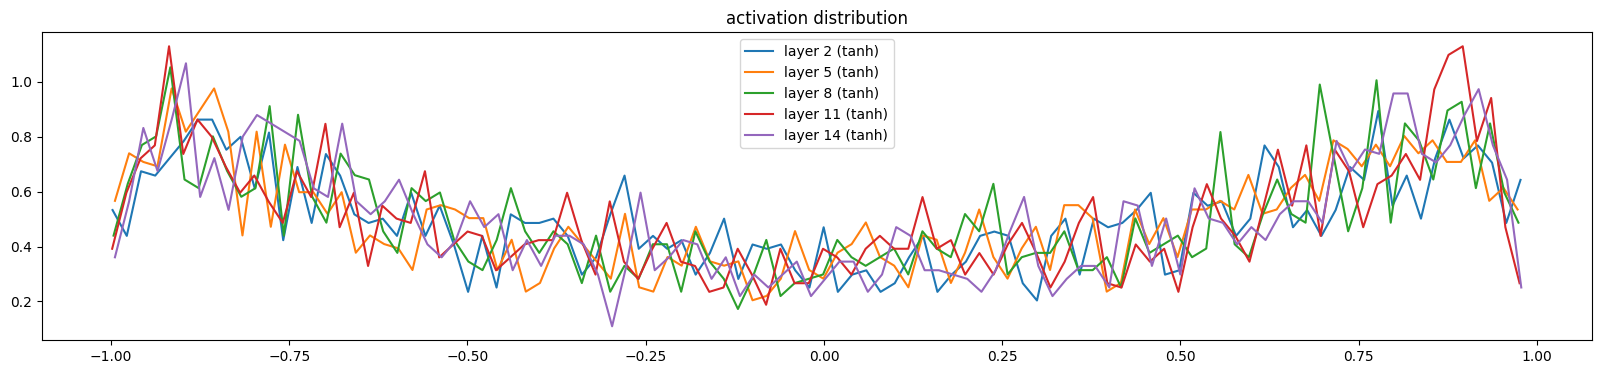

In [14]:
plt.figure(figsize=(20, 4))
legends = []
for i, layer in enumerate(Layers[:-1]):
    if isinstance(layer, tanh):
        t = layer.out.detach()
        print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1], hy)
        legends.append(f'layer {i} ({layer.__class__.__name__})')
plt.legend(legends)
plt.title('activation distribution');


#### Gradient distribution (1,000 steps)

layer %d (%10s): mean %+.2f, std %.2f
layer %d (%10s): mean %+.2f, std %.2f
layer %d (%10s): mean %+.2f, std %.2f
layer %d (%10s): mean %+.2f, std %.2f
layer %d (%10s): mean %+.2f, std %.2f


Text(0.5, 1.0, 'activation distribution')

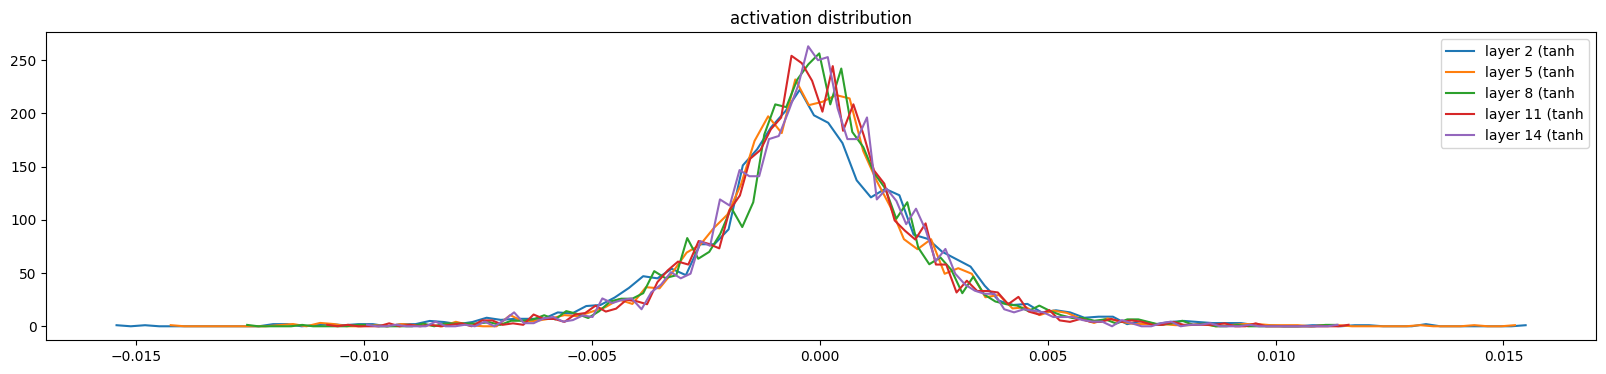

In [11]:
plt.figure(figsize=(20, 4)) 
legends = []
for i, layer in enumerate(Layers[:-1]):
    if isinstance(layer, tanh):
        t = layer.out.grad
        print('layer %d (%10s): mean %+.2f, std %.2f')
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends)
plt.title('activation distribution')


#### plotting weights' gradients

weight   (27, 10) | mean -0.000000 | std 7.433854e-03 | grad:data ratio 7.958490e-03
weight  (30, 100) | mean +0.000187 | std 6.290923e-03 | grad:data ratio 2.079102e-02
weight (100, 100) | mean +0.000028 | std 5.360375e-03 | grad:data ratio 3.188298e-02
weight (100, 100) | mean +0.000019 | std 4.783717e-03 | grad:data ratio 2.881829e-02
weight (100, 100) | mean -0.000049 | std 4.458889e-03 | grad:data ratio 2.660308e-02
weight (100, 100) | mean +0.000008 | std 4.347637e-03 | grad:data ratio 2.600304e-02
weight  (100, 27) | mean -0.000043 | std 8.334181e-03 | grad:data ratio 5.031622e-02


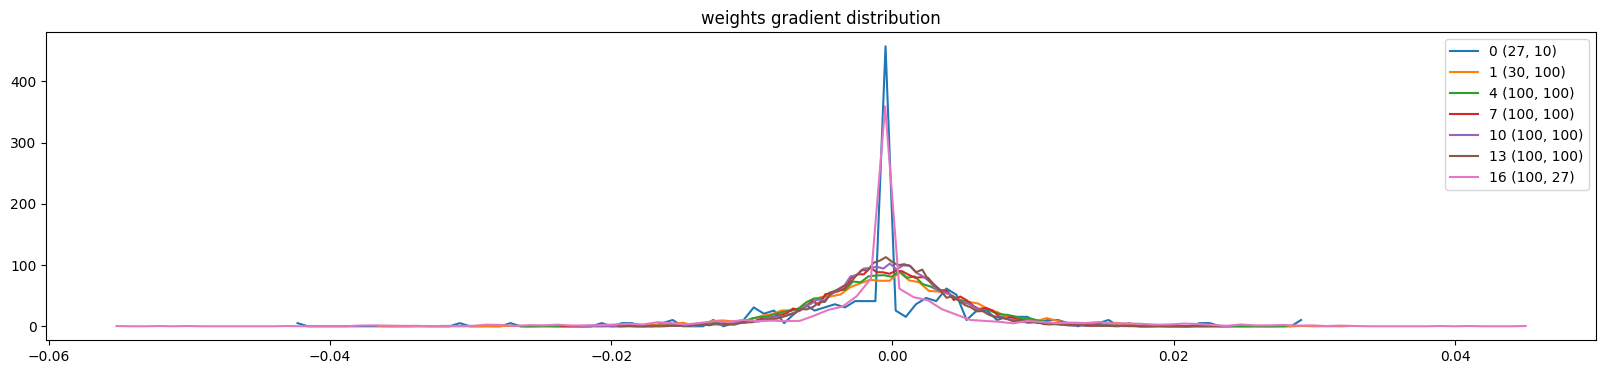

In [12]:
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
    t = p.grad
    if p.ndim == 2:
        print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
        hy, hx = torch.histogram(t, density=True)
        plt.plot(hx[:-1].detach(), hy.detach())
        legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

#### plotting update:data ratio

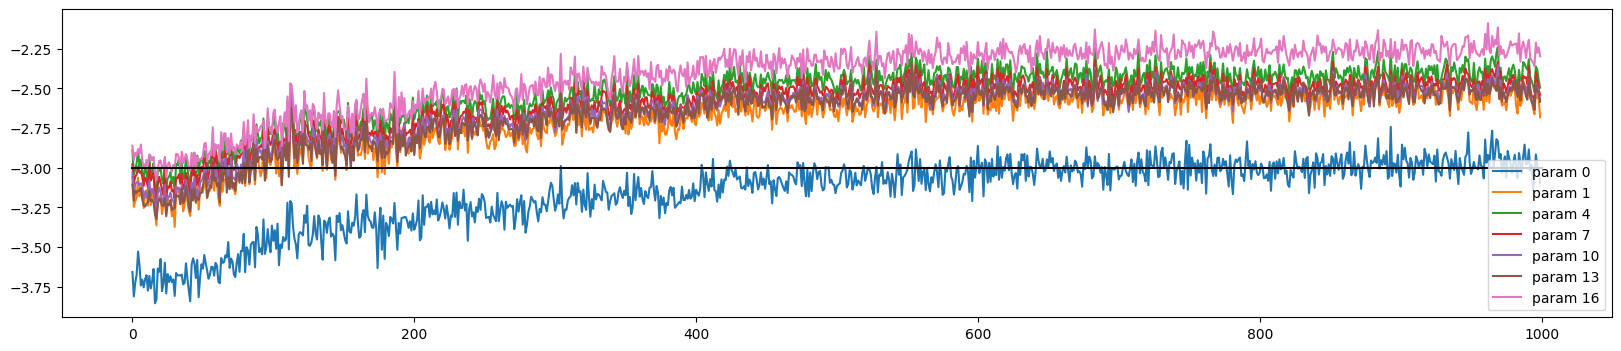

In [13]:
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
    if p.ndim == 2:
        plt.plot([ud[j][i] for j in range(len(ud))])
        legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);